# Dubai Automotive Intelligence Platform`n## 20 سوال کلیدی تحلیلی`n**Amir Kargar — Data Analysis**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
ROOT=Path(r'E:/Data_Analysis/Dubai Automotive Intelligence Platform Sales, After-Sales & EV Adoption')
CLEAN=ROOT/'02_Data_Clean'
vehicles=pd.read_csv(CLEAN/'vehicle_catalog_clean.csv')
policy=pd.read_csv(CLEAN/'uae_ev_policy_targets_clean.csv')
policy=policy[policy['indicator'].eq('EV_and_hybrid_share')].copy()
policy['ev_hybrid_share_pct']=pd.to_numeric(policy['value'])
facts=pd.read_csv(CLEAN/'public_market_facts.csv')
reviews=pd.read_csv(CLEAN/'customer_reviews_public.csv')
plt.style.use('seaborn-v0_8-whitegrid')
print(len(vehicles),len(policy),len(facts),len(reviews))

15 7 12 10


## 1. تعداد مدل هر برند چقدر است؟

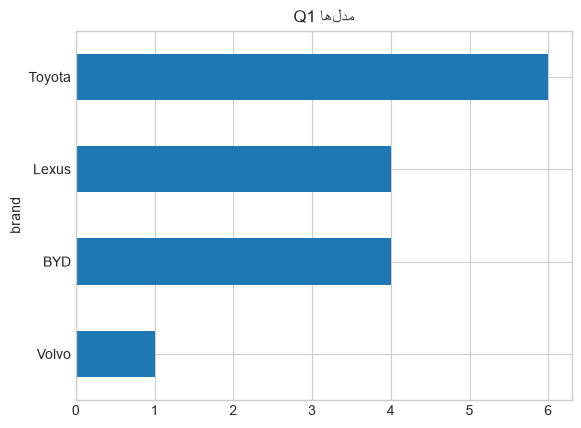

,models
brand,
Volvo,1
BYD,4
Lexus,4
Toyota,6


تحلیل: سهم فروش واقعی باید جداگانه اضافه شود.


In [2]:
x=vehicles.groupby('brand').size().sort_values(); x.plot.barh(title='Q1 مدل‌ها'); plt.show(); display(x.to_frame('models')); print('تحلیل: سهم فروش واقعی باید جداگانه اضافه شود.')

## 2. ترکیب قوای محرکه هر برند چیست؟

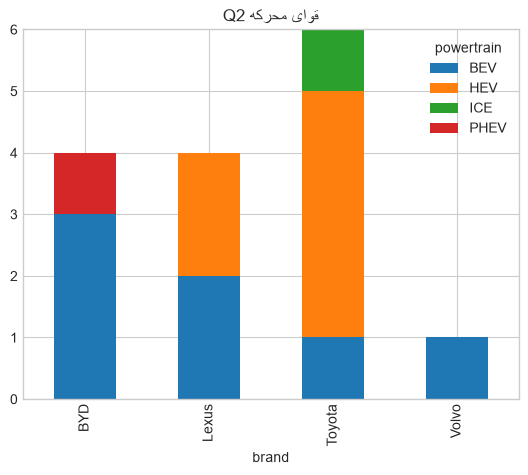

تحلیل: تنوع بیشتر یعنی پوشش بهتر و پیچیدگی خدمات بالاتر.


In [3]:
x=pd.crosstab(vehicles.brand,vehicles.powertrain); x.plot.bar(stacked=True,title='Q2 قوای محرکه'); plt.show(); print('تحلیل: تنوع بیشتر یعنی پوشش بهتر و پیچیدگی خدمات بالاتر.')

## 3. سهم مدل‌های برقی و هیبریدی چقدر است؟

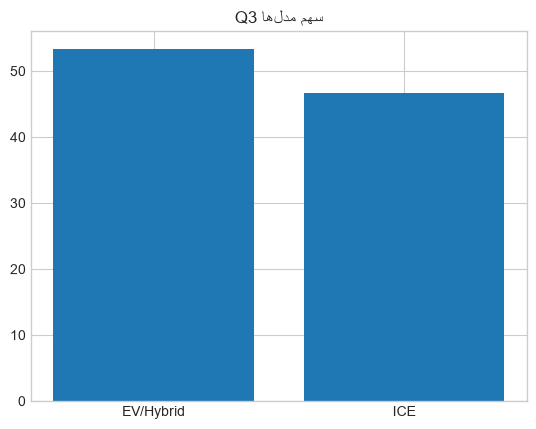

53.333333333333336
تحلیل: این سهم مدل‌هاست نه سهم فروش.


In [4]:
s=vehicles.powertrain.isin(['BEV','PHEV','Hybrid']).mean()*100; plt.bar(['EV/Hybrid','ICE'],[s,100-s]); plt.title('Q3 سهم مدل‌ها'); plt.show(); print(s); print('تحلیل: این سهم مدل‌هاست نه سهم فروش.')

## 4. قیمت مدل‌های برقی چه توزیعی دارد؟

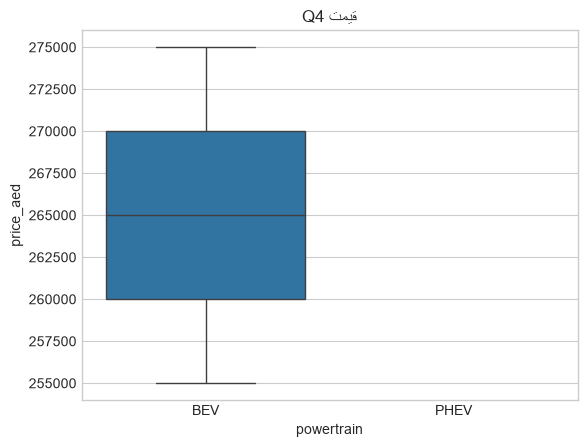

تحلیل: شکاف قیمتی فرصت لیزینگ است.


In [5]:
x=vehicles[vehicles.powertrain.isin(['BEV','PHEV','Hybrid'])]; sns.boxplot(data=x,x='powertrain',y='price_aed'); plt.title('Q4 قیمت'); plt.show(); print('تحلیل: شکاف قیمتی فرصت لیزینگ است.')

## 5. اقتصادی‌ترین مدل‌های برقی کدام‌اند؟

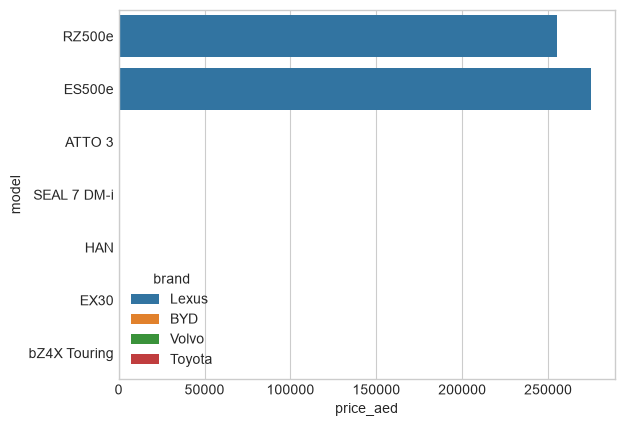

,catalog_id,distributor,brand,model,vehicle_type,powertrain,trim,range_km_wltp,battery_kwh,max_power_kw,transmission,price_aed,market,status,source_url,source_id,is_electrified,price_per_range_km
11,VC012,Al-Futtaim Automotive,Lexus,RZ500e,SUV,BEV,2026 Platinum,NaN,NaN,NaN,NaN,255000.0,UAE,verified_public,https://www.lexus.ae/en/,SRC014,True,NaN
10,VC011,Al-Futtaim Automotive,Lexus,ES500e,Sedan,BEV,2026,NaN,NaN,NaN,NaN,275000.0,UAE,verified_public,https://www.lexus.ae/en/,SRC014,True,NaN
0,VC001,Al-Futtaim Automotive,BYD,ATTO 3,SUV,BEV,Comfort,420.0,60.48,150.0,NaN,NaN,UAE,verified_public,https://dam.alfuttaim.com/wps/wcm/connect/33b3...,SRC008,True,NaN
1,VC002,Al-Futtaim Automotive,BYD,ATTO 3,SUV,BEV,Premium,NaN,NaN,NaN,NaN,NaN,UAE,model_confirmed_specs_pending,https://www.alfuttaim.com/en/our-brands/byd/,SRC002,True,NaN
2,VC003,Al-Futtaim Electric Mobility,BYD,SEAL 7 DM-i,Sedan,PHEV,NaN,NaN,NaN,NaN,NaN,NaN,UAE,model_confirmed_specs_pending,https://www.alfuttaim.com/en/articles/al-futta...,SRC009,True,NaN
3,VC004,Al-Futtaim Automotive,BYD,HAN,Sedan,BEV,AWD,NaN,NaN,NaN,NaN,NaN,UAE,model_confirmed_specs_pending,https://dam.alfuttaim.com/wps/wcm/connect/1d07...,SRC010,True,NaN
4,VC005,Al-Futtaim Automotive,Volvo,EX30,SUV,BEV,NaN,NaN,NaN,NaN,NaN,NaN,UAE,model_confirmed_specs_pending,https://www.volvocars.com/en-ae/cars/electric-...,SRC011,True,NaN
14,VC015,Al-Futtaim Automotive,Toyota,bZ4X Touring,SUV,BEV,2026 VXR,NaN,NaN,NaN,NaN,NaN,UAE,model_confirmed_specs_pending,https://www.toyota.ae/en/site-map/,SRC015,True,NaN


تحلیل: مناسب تست‌درایو و فلیت شهری.


In [6]:
x=vehicles[vehicles.powertrain.isin(['BEV','PHEV','Hybrid'])].nsmallest(10,'price_aed'); sns.barplot(data=x,y='model',x='price_aed',hue='brand',dodge=False); plt.show(); display(x); print('تحلیل: مناسب تست‌درایو و فلیت شهری.')

## 6. رابطه قیمت و قوای محرکه چیست؟

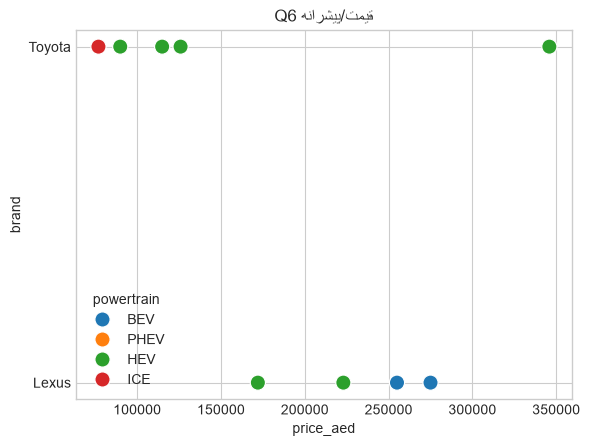

تحلیل: EV پریمیوم مانع پذیرش قیمتی است.


In [7]:
sns.scatterplot(data=vehicles,x='price_aed',y='brand',hue='powertrain',s=120); plt.title('Q6 قیمت/پیشرانه'); plt.show(); print('تحلیل: EV پریمیوم مانع پذیرش قیمتی است.')

## 7. مسیر هدف EV/Hybrid امارات چیست؟

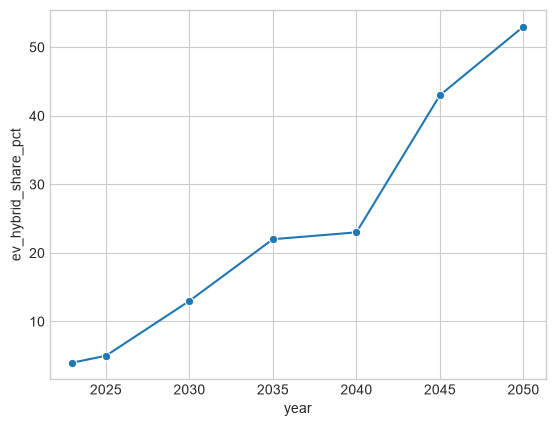

,year,ev_hybrid_share_pct
0,2023,4
1,2025,5
2,2030,13
3,2035,22
4,2040,23
5,2045,43
6,2050,53


تحلیل: نیاز به برنامه مرحله‌ای موجودی و خدمات.


In [8]:
x=policy.sort_values('year'); sns.lineplot(data=x,x='year',y='ev_hybrid_share_pct',marker='o'); plt.show(); display(x[['year','ev_hybrid_share_pct']]); print('تحلیل: نیاز به برنامه مرحله‌ای موجودی و خدمات.')

## 8. فاصله اهداف سیاستی با پایه چقدر است؟

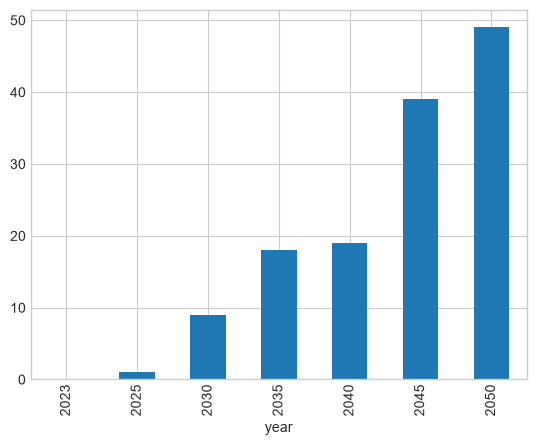

تحلیل: فاصله سیاستی بازار خدمات مکمل می‌سازد.


In [9]:
x=policy.sort_values('year').copy(); x['gap']=x.ev_hybrid_share_pct-x.ev_hybrid_share_pct.iloc[0]; x.plot.bar(x='year',y='gap',legend=False); plt.show(); print('تحلیل: فاصله سیاستی بازار خدمات مکمل می‌سازد.')

## 9. روند نقاط شارژ هدف‌گذاری‌شده چیست؟

In [10]:
x=policy.dropna(subset=['charging_points']); sns.lineplot(data=x,x='year',y='charging_points',marker='o'); plt.show(); print('تحلیل: نصب و نگهداری شارژر فرصت است.')

KeyError: ['charging_points']

## 10. نقاط تماس اکوسیستم شرکت کدام‌اند؟

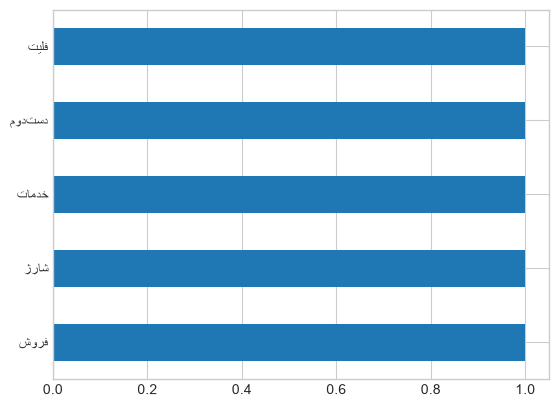

تحلیل: سفر مشتری از فروش تا فروش مجدد قابل مدل‌سازی است.


In [11]:
x=pd.Series({'فروش':1,'شارژ':1,'خدمات':1,'دست‌دوم':1,'فلیت':1}); x.plot.barh(); plt.show(); print('تحلیل: سفر مشتری از فروش تا فروش مجدد قابل مدل‌سازی است.')

## 11. امتیاز خدمات برندها چگونه است؟

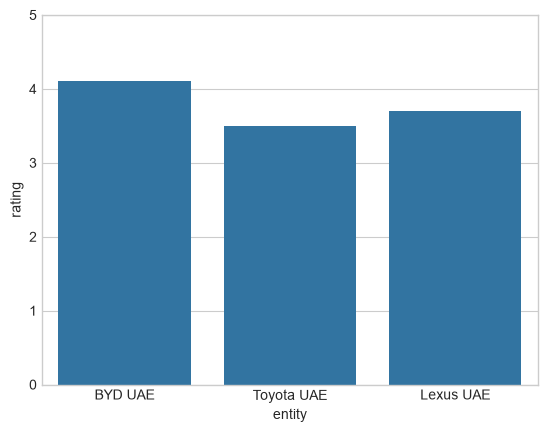

,entity,rating,review_count
1,BYD UAE,4.1,204
3,Toyota UAE,3.5,46
4,Lexus UAE,3.7,87


تحلیل: امتیاز باید با شعبه و زمان انتظار بررسی شود.


In [12]:
x=reviews[reviews.review_type=='aggregated service rating']; sns.barplot(data=x,x='entity',y='rating'); plt.ylim(0,5); plt.show(); display(x[['entity','rating','review_count']]); print('تحلیل: امتیاز باید با شعبه و زمان انتظار بررسی شود.')

## 12. حجم نمونه نظرات کافی است؟

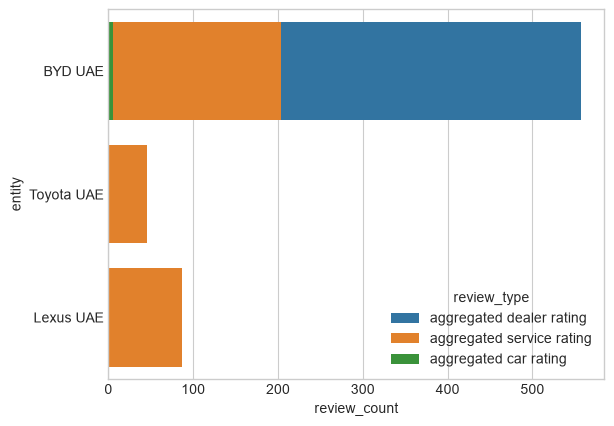

تحلیل: امتیاز بدون حجم نمونه کافی قابل اتکا نیست.


In [13]:
x=reviews[reviews.review_type.str.startswith('aggregated')]; sns.barplot(data=x,x='review_count',y='entity',hue='review_type',dodge=False); plt.show(); print('تحلیل: امتیاز بدون حجم نمونه کافی قابل اتکا نیست.')

## 13. موضوعات منفی پرتکرار چیست؟

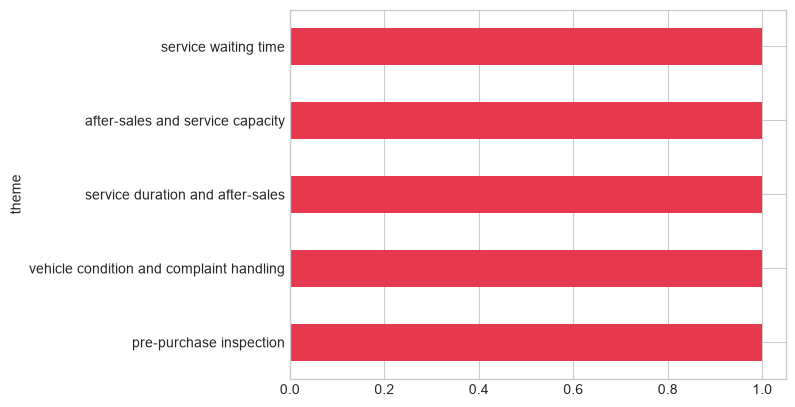

theme
pre-purchase inspection                     1
vehicle condition and complaint handling    1
service duration and after-sales            1
after-sales and service capacity            1
service waiting time                        1
Name: count, dtype: int64
تحلیل: زمان خدمات و شفافیت دست‌دوم محورهای اصلی‌اند.


In [14]:
x=reviews[reviews.sentiment=='negative'].theme.value_counts(); x.plot.barh(color='#E63950'); plt.show(); print(x); print('تحلیل: زمان خدمات و شفافیت دست‌دوم محورهای اصلی‌اند.')

## 14. کیفیت منابع نظرات چقدر است؟

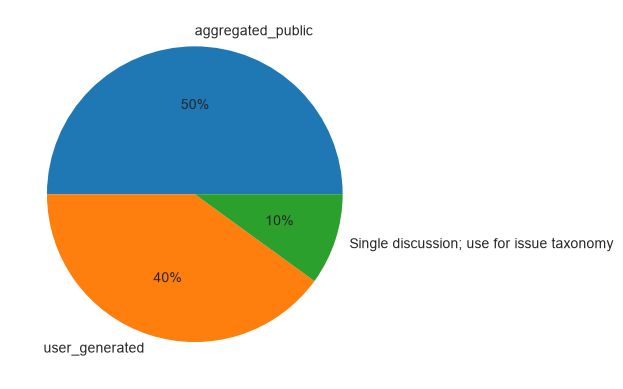

تحلیل: روایت فردی برای فرضیه است نه KPI قطعی.


In [15]:
x=reviews.source_status.value_counts(); x.plot.pie(autopct='%1.0f%%'); plt.show(); print('تحلیل: روایت فردی برای فرضیه است نه KPI قطعی.')

## 15. Automall چه فرصت تحلیلی دارد؟

,metric,value,unit
2,inspection_points,99,points
9,automall_showrooms,2,showrooms


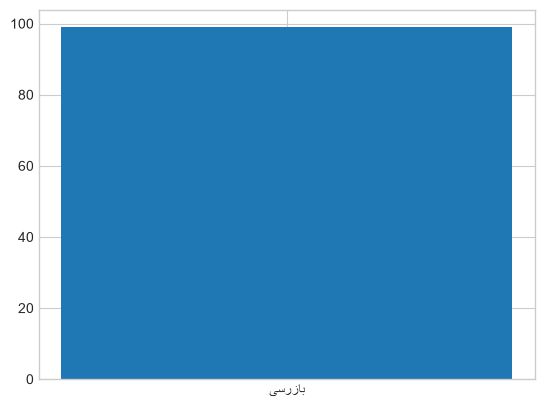

تحلیل: نرخ تبدیل بازرسی به خرید باید اندازه‌گیری شود.


In [16]:
x=facts[facts.category=='used_cars']; display(x[['metric','value','unit']]); plt.bar(['بازرسی'],[99]); plt.show(); print('تحلیل: نرخ تبدیل بازرسی به خرید باید اندازه‌گیری شود.')

## 16. ظرفیت فلیت اجاره‌ای چقدر است؟

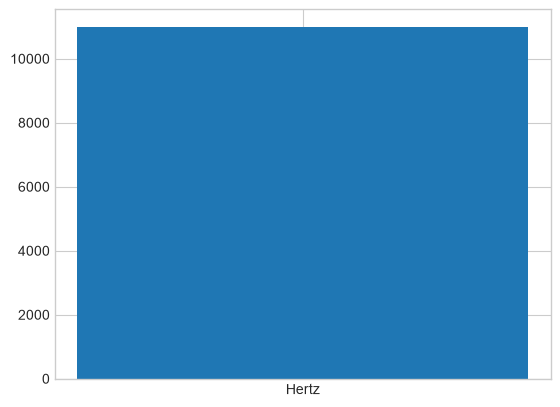

11000
تحلیل: utilization و downtime داده‌های بعدی هستند.


In [17]:
x=facts[facts.metric=='hertz_fleet_size'].iloc[0]; plt.bar(['Hertz'],[float(x.value)]); plt.show(); print(x.value); print('تحلیل: utilization و downtime داده‌های بعدی هستند.')

## 17. فرصت فلیت تجاری چه ابعادی دارد؟

,metric,value,unit
7,aircraft_catering_trucks,53,vehicles
8,investment,60000000,AED


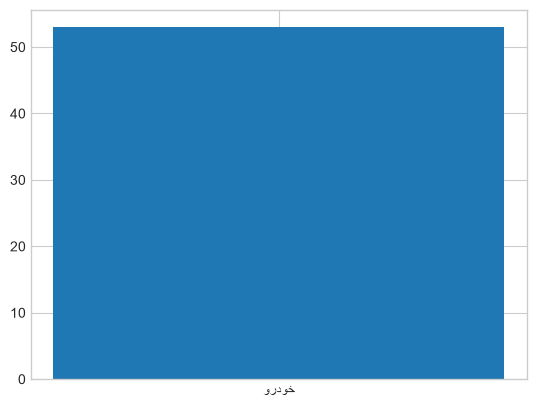

تحلیل: هزینه چرخه عمر و نوسازی مهم است.


In [21]:
x=facts[facts.category=='fleet_case']; display(x[['metric','value','unit']]); plt.bar(['خودرو'],[53]); plt.show(); print('تحلیل: هزینه چرخه عمر و نوسازی مهم است.')

## 18. پوشش مدل فعلی با هدف سیاستی هم‌راستاست؟

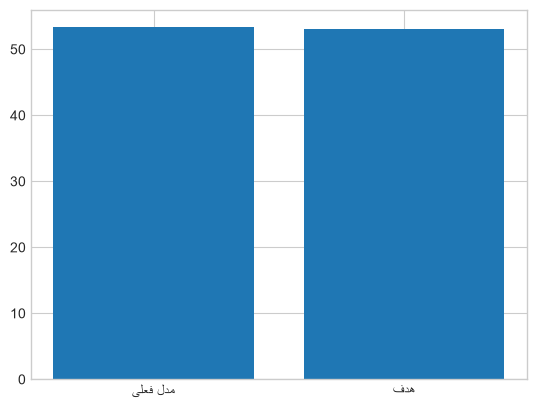

53.333333333333336 53
تحلیل: این مقایسه مستقیم فروش نیست اما هشدار برنامه مدل است.


In [20]:
a=vehicles.powertrain.isin(['BEV','PHEV','Hybrid']).mean()*100; b=policy.ev_hybrid_share_pct.iloc[-1]; plt.bar(['مدل فعلی','هدف'],[a,b]); plt.show(); print(a,b); print('تحلیل: این مقایسه مستقیم فروش نیست اما هشدار برنامه مدل است.')

## 19. مهم‌ترین شکاف داده‌ای چیست؟

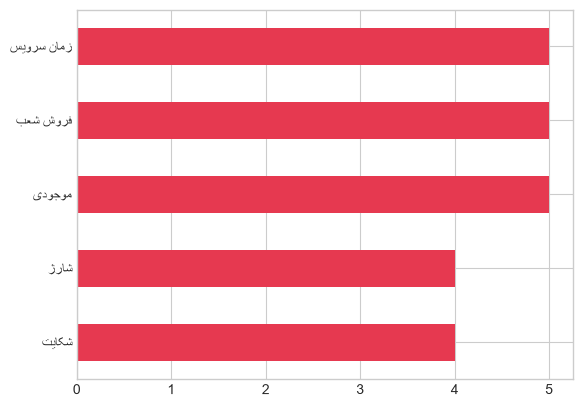

تحلیل: اول فروش، سفارش و after-sales را متصل کنید.


In [19]:
x=pd.Series({'فروش شعب':5,'موجودی':5,'زمان سرویس':5,'شکایت':4,'شارژ':4}); x.sort_values().plot.barh(color='#E63950'); plt.show(); print('تحلیل: اول فروش، سفارش و after-sales را متصل کنید.')

## 20. سه اقدام اولویت‌دار چیست؟

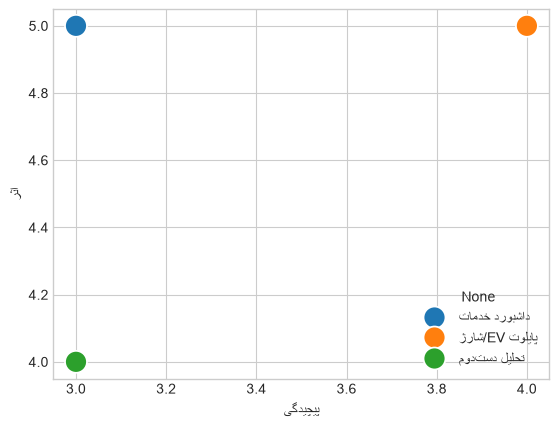

,اثر,پیچیدگی
داشبورد خدمات,5,3
پایلوت EV/شارژ,5,4
تحلیل دست‌دوم,4,3


جمع‌بندی: داشبورد خدمات، پایلوت EV و کنترل کیفیت دست‌دوم.


In [18]:
x=pd.DataFrame({'اثر':[5,5,4],'پیچیدگی':[3,4,3]},index=['داشبورد خدمات','پایلوت EV/شارژ','تحلیل دست‌دوم']); sns.scatterplot(data=x,x='پیچیدگی',y='اثر',hue=x.index,s=250); plt.show(); display(x); print('جمع‌بندی: داشبورد خدمات، پایلوت EV و کنترل کیفیت دست‌دوم.')

## نتیجه نهایی`nبرای نسخه عملیاتی، فروش شعب، CRM، زمان سرویس، قطعات، شکایت، NPS، قرارداد فلیت و مصرف شارژ باید اضافه شوند.`n`n**Amir Kargar — Data Analysis**